# Homework 1: Neural-Network Foundations in PyTorch (Weeks 1-2)

**DLE-AI-202 Deep Learning, Cohort II.** Read `statement.pdf` first: it has the written problems (Part A), the marking policy and the submission rules.
This notebook is the **coding half**: you complete the functions in `src/`, check them with `pytest`, and then use them to run four small experiments.

**How to work**
1. Do the parts in order. Each part has a *test cell*: run it, read the failures, fix `src/`, run again. Green tests are your feedback, they are not hidden.
2. Edit the Python files in `src/` (any editor), then use **Kernel -> Restart** or the `%autoreload` line below so the notebook sees your changes.
3. Experiments (Part E) use *your* functions, so finish B1-B5 first.
4. Keep the keyboard shortcuts of the **torch cheatsheet** (`torch_cheatsheet.ipynb`) open next to this notebook.

| Part | What | Where |
|------|------|-------|
| B1 | tensor basics and the Week-1 losses | `src/tensor_basics.py` |
| B2 | manual backpropagation + custom autograd Function | `src/manual_mlp.py` |
| B3 | the `MLP` module and initialisation | `src/model.py` |
| B4 | training utilities: schedule, epoch, evaluate, `fit` | `src/train.py` |
| B5 | diagnostics with hooks | `src/diagnostics.py` |
| E | experiments: initialisation/depth, optimisers, regularisation, final model | this notebook |
| C | reflection and AI disclosure | this notebook + `report_template.tex` |

## 0. Setup

In [1]:
%load_ext autoreload
%autoreload 2
import os, sys
sys.path.insert(0, "src")
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

from data import student_seed, set_seed, load_digits_splits, make_loader, corrupt_labels
from plotting import plot_histories, plot_layer_stats
import tensor_basics as tb, manual_mlp as mm
from model import MLP, init_weights, count_params
from train import warmup_cosine, train_one_epoch, evaluate, fit
from diagnostics import layer_stats, dead_relu_fraction, overfit_one_batch

# Your seed comes from your Academy ID:  STUDENT_ID=12345 jupyter lab   (or set it in the next line)
os.environ.setdefault("STUDENT_ID", "0")
SEED = student_seed()
set_seed(SEED)
print("torch", torch.__version__, "| STUDENT_ID =", os.environ["STUDENT_ID"], "| seed =", SEED, "| threads =", torch.get_num_threads())

torch 2.7.1+cpu | STUDENT_ID = 0 | seed = 0 | threads = 1


{'Xtr': (1000, 64), 'ytr': (1000,), 'Xva': (300, 64), 'yva': (300,), 'Xte': (497, 64), 'yte': (497,)} torch.float32 torch.int64


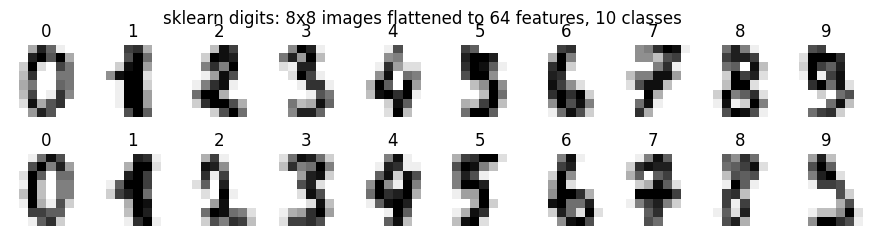

In [2]:
D = load_digits_splits(SEED)                      # standardised with TRAIN statistics only
print({k: tuple(v.shape) for k, v in D.items()}, D["Xtr"].dtype, D["ytr"].dtype)
tr_loader = make_loader(D["Xtr"], D["ytr"], 64, True, SEED)
va_loader = make_loader(D["Xva"], D["yva"], 256, False)
te_loader = make_loader(D["Xte"], D["yte"], 256, False)

from sklearn.datasets import load_digits
raw = load_digits()
fig, axs = plt.subplots(2, 10, figsize=(11, 2.6))
for i, ax in enumerate(axs.flat): ax.imshow(raw.images[i], cmap="gray_r"); ax.set_title(raw.target[i]); ax.axis("off")
plt.suptitle("sklearn digits: 8x8 images flattened to 64 features, 10 classes"); plt.show()

## B1. Tensor basics and the Week-1 losses (10 pts)
Implement `standardize`, `one_hot`, `pairwise_sq_dists`, `softmax`, `log_softmax`, `cross_entropy`, `bce_with_logits` and `mse` in `src/tensor_basics.py`
using **raw tensor operations** (no `F.cross_entropy`, `torch.softmax`, ...: those are your reference in the tests).
Two things to watch: *numerical stability* (subtract the max, use `logsumexp`) and *shapes* (`(n,)` vs `(n,1)`).

In [3]:
!{sys.executable} -m pytest tests/test_b1_tensor_basics.py -q 2>&1 | tail -15

"tail" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.


In [4]:
# A quick feel for stability: the naive formula overflows, yours should not.
z = torch.tensor([[1000.0, 1001.0, 999.0]])
naive = torch.exp(z) / torch.exp(z).sum(1, keepdim=True)
print("naive softmax :", naive)
print("your softmax  :", tb.softmax(z))
print("your CE (true class 2) :", tb.cross_entropy(torch.tensor([[2000.0, 0.0, -2000.0]]), torch.tensor([2])).item(), "(finite, large)")

naive softmax : tensor([[nan, nan, nan]])
your softmax  : tensor([[0.2447, 0.6652, 0.0900]])
your CE (true class 2) : 4000.0 (finite, large)


## B2. Backpropagation by hand, and a custom autograd Function (10 pts)
In `src/manual_mlp.py` you code the backward pass of a 2-layer MLP **with the backpropagation equations of Week 2** (no `.backward()`), a finite-difference gradient checker,
and `SwishFn`, an `autograd.Function` with its own backward. The tests compare against `torch.autograd`.

In [5]:
!{sys.executable} -m pytest tests/test_b2_manual_backprop.py -q 2>&1 | tail -15

"tail" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.


In [6]:
# Compare your manual gradients with autograd on a random problem (float64), as the tests do.
params = mm.init_params(d=5, h=6, K=3, seed=SEED)
X = torch.randn(7, 5, dtype=torch.float64); y = torch.randint(0, 3, (7,))
for act in ("tanh", "relu"):
    logits, cache = mm.forward(params, X, act)
    grads = mm.backward(params, cache, logits, y, act)
    leaf = {k: v.clone().requires_grad_(True) for k, v in params.items()}
    F.cross_entropy(mm.forward(leaf, X, act)[0], y).backward()
    print(act, {k: f"{(grads[k] - leaf[k].grad).abs().max().item():.1e}" for k in grads})

tanh {'W1': '2.8e-17', 'b1': '2.4e-17', 'W2': '5.6e-17', 'b2': '1.1e-16'}
relu {'W1': '8.3e-17', 'b1': '5.6e-17', 'W2': '1.1e-16', 'b2': '5.6e-17'}


**Check your hand calculation of Problem A3.** The cell below computes the same network with autograd. Fill in *your* hand-computed gradient of the loss with respect to
`W1` (a 2x2 matrix in the statement's column convention, `z1 = W1 @ x + b1`) and compare. Note that `nn.Linear` and the batch-first code of B2 store the *transpose*.

In [7]:
x  = torch.tensor([1., 2.]);  y_onehot = torch.tensor([1., 0.])
W1 = torch.tensor([[1., -1.], [2., 0.]], requires_grad=True);  b1 = torch.tensor([0., -1.], requires_grad=True)
W2 = torch.tensor([[1., 1.], [-1., 2.]], requires_grad=True);  b2 = torch.zeros(2, requires_grad=True)
z1 = W1 @ x + b1; h = torch.relu(z1); z2 = W2 @ h + b2
L = -(y_onehot * torch.log_softmax(z2, 0)).sum(); L.backward()
print("z1 =", z1.detach(), " h =", h.detach(), " logits =", z2.detach(), " L =", round(L.item(), 4))
print("dL/dW1 =\n", W1.grad, "\ndL/dW2 =\n", W2.grad)

my_dW1 = torch.tensor([[0.0, 0.0], [0.7311, 1.4621]])
if my_dW1 is not None: print("matches autograd:", torch.allclose(my_dW1, W1.grad, atol=1e-3))

z1 = tensor([-1.,  1.])  h = tensor([0., 1.])  logits = tensor([1., 2.])  L = 1.3133
dL/dW1 =
 tensor([[0.0000, 0.0000],
        [0.7311, 1.4621]]) 
dL/dW2 =
 tensor([[-0.0000, -0.7311],
        [ 0.0000,  0.7311]])
matches autograd: True


## B3. The `MLP` module and initialisation (8 pts)
Implement `MLP`, `init_weights` (He, Xavier, normal, zeros, written from the variance formulas) and `count_params` in `src/model.py`.

In [8]:
!{sys.executable} -m pytest tests/test_b3_model.py -q 2>&1 | tail -15

"tail" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.


In [9]:
set_seed(SEED)
net = MLP(64, [128, 64], 10, act="relu", dropout=0.2, norm="batch"); init_weights(net, "he")
print(net, "\nparameters:", count_params(net))
print("first-layer weight std:", net.net[0].weight.std().item(), "| He formula sqrt(2/64) =", (2 / 64) ** 0.5)

MLP(
  (net): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): Linear(in_features=64, out_features=10, bias=True)
  )
) 
parameters: 17610
first-layer weight std: 0.17714890837669373 | He formula sqrt(2/64) = 0.1767766952966369


## B4. Training utilities (12 pts)
Implement `warmup_cosine`, `accuracy_from_logits`, `train_one_epoch`, `evaluate` and `fit` (history, early stopping, **restore best weights**) in `src/train.py`.
Follow the order *zero_grad, forward, loss, backward, clip, step, scheduler.step*; evaluation uses `model.eval()` and `torch.no_grad()`.

In [10]:
!{sys.executable} -m pytest tests/test_b4_training.py -q 2>&1 | tail -15

"tail" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.


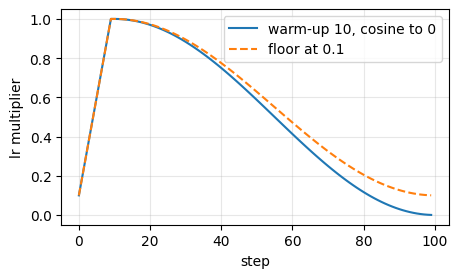

In [11]:
steps = np.arange(0, 100)
plt.figure(figsize=(5, 2.8))
plt.plot(steps, [warmup_cosine(int(s), 10, 100) for s in steps], label="warm-up 10, cosine to 0")
plt.plot(steps, [warmup_cosine(int(s), 10, 100, min_factor=0.1) for s in steps], "--", label="floor at 0.1")
plt.xlabel("step"); plt.ylabel("lr multiplier"); plt.grid(alpha=.3); plt.legend(); plt.show()

## B5. Diagnostics with hooks (5 pts)
Implement `layer_stats`, `dead_relu_fraction` and `overfit_one_batch` in `src/diagnostics.py`. These are the tools of Week 1; Part E uses them.

In [12]:
!{sys.executable} -m pytest tests/test_b5_diagnostics.py -q 2>&1 | tail -15

"tail" �� ���� ����७��� ��� ���譥�
��������, �ᯮ��塞�� �ணࠬ��� ��� ������ 䠩���.


In [13]:
# The two sanity checks to run on ANY new model before a long experiment:
set_seed(SEED)
m = MLP(64, [64, 64], 10); init_weights(m, "he")
Xb, yb = D["Xtr"][:32], D["ytr"][:32]
print("initial loss:", F.cross_entropy(m(Xb), yb).item(), "| ln(10) =", np.log(10).round(3), "(He init gives logits with std ~1, so the loss starts somewhat above ln 10; far above, e.g. 10+, would signal a bug)")
print("overfit one batch ->", overfit_one_batch(m, Xb, yb, steps=300, lr=1e-2), "(loss, accuracy)")

initial loss: 2.9859554767608643 | ln(10) = 2.303 (He init gives logits with std ~1, so the loss starts somewhat above ln 10; far above, e.g. 10+, would signal a bug)
overfit one batch -> (3.2707844184187707e-06, 1.0) (loss, accuracy)


---
# Part E. Experiments (15 pts)
All experiments use *your* code. Use the seed from your Academy ID, keep everything else as given unless the text says otherwise.
Each experiment ends with a short written answer (3-5 sentences, **your own words, citing your own numbers**); copy these answers into `report_template.tex`.

## E1. Deep networks: why initialisation and activation matter
We build a 10-hidden-layer MLP (width 64) in four ways and measure, **at initialisation**, the std of every layer's output and the gradient norm of every layer's weights,
then train each with plain SGD for 20 epochs.

In [14]:
configs = {"sigmoid + xavier": ("sigmoid", "xavier"), "relu + normal(0.01)": ("relu", "normal"),
           "relu + xavier": ("relu", "xavier"), "relu + he": ("relu", "he")}
stats, hist_deep = {}, {}
for name, (act, init) in configs.items():
    set_seed(SEED)
    model = MLP(64, [64] * 10, 10, act=act)
    init_weights(model, init)
    stats[name] = layer_stats(model, D["Xtr"][:128], D["ytr"][:128])
    opt = torch.optim.SGD(model.parameters(), lr=0.05)
    hist_deep[name] = fit(model, tr_loader, va_loader, opt, epochs=20)

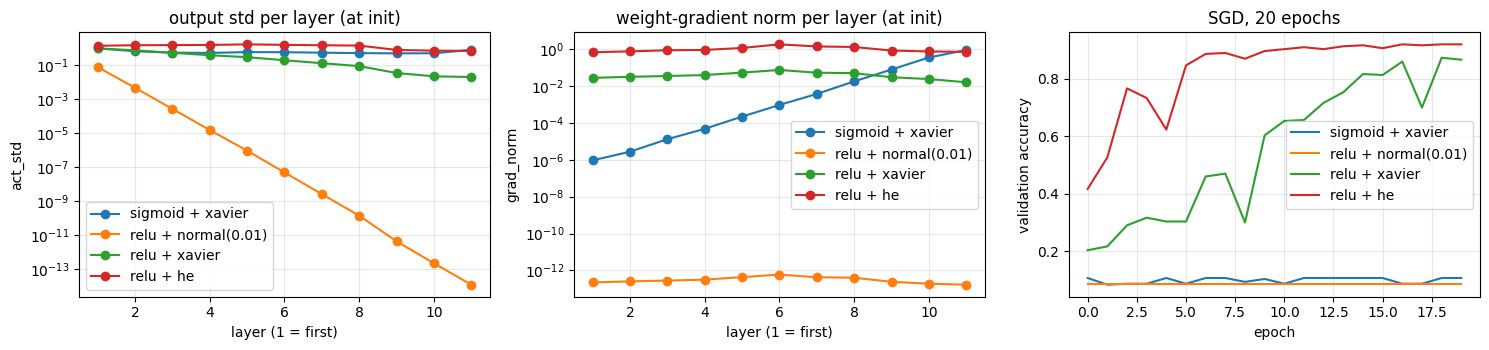

sigmoid + xavier       grad(layer1)/grad(last) = 1.05e-06 | final val acc = 0.107
relu + normal(0.01)    grad(layer1)/grad(last) = 1.32e+00 | final val acc = 0.087
relu + xavier          grad(layer1)/grad(last) = 1.73e+00 | final val acc = 0.867
relu + he              grad(layer1)/grad(last) = 9.41e-01 | final val acc = 0.920


In [15]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
plot_layer_stats(stats, "act_std", ax[0], title="output std per layer (at init)")
plot_layer_stats(stats, "grad_norm", ax[1], title="weight-gradient norm per layer (at init)")
plot_histories(hist_deep, "val_acc", "validation accuracy", ax[2], title="SGD, 20 epochs"); plt.tight_layout(); plt.show()
for name, s in stats.items():
    print(f"{name:22s} grad(layer1)/grad(last) = {s[0]['grad_norm'] / s[-1]['grad_norm']:.2e} | final val acc = {hist_deep[name]['val_acc'][-1]:.3f}")

> **Your answer.** Which configurations failed to train, and why? Use the printed ratios and the two left plots, and connect each failure to a mechanism from Week 1 (saturation, vanishing signal, variance).
>
> In the 10-layer MLP, sigmoid + xavier maintains stable activation variance ($\sim 0.4$) but suffers severe vanishing gradients ($\text{grad}_1/\text{grad}_{11} = 1.05 \times 10^{-6}$), stalling at chance accuracy (0.107). relu + normal(0.01) collapses activations exponentially down to $\sim 10^{-14}$ across depth, yielding near-zero gradients ($\sim 10^{-13}$) at every layer and failing to learn (0.087). relu + xavier loses roughly half the signal variance per layer (decaying from $\sim 0.7$ to $\sim 0.02$), resulting in slower, noisier convergence (0.867). Finally, relu + he compensates for ReLU's half-rectification to keep both activations ($\sim 1.0$) and gradients ($\sim 1.0$, ratio 0.941) constant across all 11 layers, converging fastest to the highest validation accuracy (0.920).

## E2. Optimisers on the same problem
Train the same MLP (`[128, 64]`, He init) for 30 epochs with five optimisers, same seed and data. Plot validation loss versus epoch.

In [16]:
optimizers = {
    "SGD":      lambda p: torch.optim.SGD(p, lr=0.05),
    "SGD+mom":  lambda p: torch.optim.SGD(p, lr=0.05, momentum=0.9),
    "RMSprop":  lambda p: torch.optim.RMSprop(p, lr=1e-3),
    "Adam":     lambda p: torch.optim.Adam(p, lr=1e-3),
    "AdamW":    lambda p: torch.optim.AdamW(p, lr=1e-3, weight_decay=0.05),
}
hist_opt = {}
for name, make_opt in optimizers.items():
    set_seed(SEED)
    model = MLP(64, [128, 64], 10, act="relu")
    init_weights(model, "he")
    opt = make_opt(model.parameters())
    hist_opt[name] = fit(model, tr_loader, va_loader, opt, epochs=30)

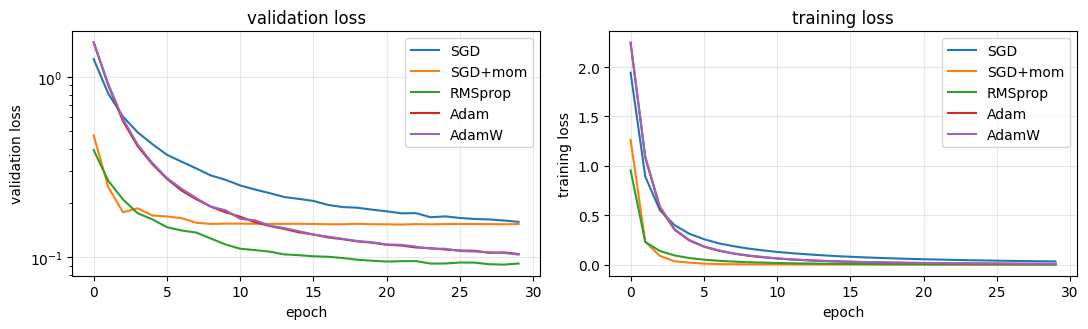

{'SGD': 0.947, 'SGD+mom': 0.963, 'RMSprop': 0.973, 'Adam': 0.963, 'AdamW': 0.96}


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
plot_histories(hist_opt, "val_loss", "validation loss", ax[0], title="validation loss")
plot_histories(hist_opt, "train_loss", "training loss", ax[1], title="training loss"); ax[0].set_yscale("log"); plt.tight_layout(); plt.show()
print({k: round(h["val_acc"][-1], 3) for k, h in hist_opt.items()})

> **Your answer.** Which optimiser reduced the validation loss fastest in the first 5 epochs, and which was best at epoch 30? Explain the difference using what each optimiser does with the gradient (momentum, per-parameter scaling, bias correction). Say why one comparison at one learning rate does not prove one optimiser is better.
>
> SGD+mom and RMSprop reduce validation loss fastest in the first 5 epochs, while RMSprop is best at epoch 30 with the lowest validation loss (below 0.10) and highest validation accuracy (0.973), compared to 0.947 for plain SGD and 0.960 to 0.963 for SGD+mom, Adam, and AdamW. Momentum accelerates progress along consistent descent directions by accumulating an exponential moving average of past gradients, whereas RMSprop, Adam, and AdamW divide updates by the root mean square of past gradients for per-parameter step scaling (with Adam and AdamW also adding bias correction so early moment estimates are not shrunk toward zero). However, comparing optimizers at a single fixed learning rate does not prove one is universally better because each optimizer has a different optimal learning-rate scale and sensitivity to hyperparameters.  

## E3. Regularisation on a small, noisy dataset
To make overfitting visible we keep only **300 training images** and replace **25% of their labels** with a wrong class (`corrupt_labels`): noise cannot be learned, only memorised.
Validation and test labels stay clean. Model: `MLP(64, [256, 256], 10)`, He init, `AdamW(lr=1e-3)`, up to 100 epochs. Run every configuration below and record the history and the test result.

Note: `fit` always restores the best weights, so `evaluate` after `fit` reports the model at its best validation epoch. The **last-epoch** numbers in the history show what would happen without early stopping.

In [18]:
import torch.nn.functional as F
from bonus import mixup_batch  # or `from bonus import mixup_batch` depending on filename

D_small = load_digits_splits(SEED, n_train=300)
y_noisy = corrupt_labels(D_small["ytr"], 0.25, seed=SEED)
tr_s = make_loader(D_small["Xtr"], y_noisy, 32, True, SEED)
va_s = make_loader(D_small["Xva"], D_small["yva"], 256, False)
te_s = make_loader(D_small["Xte"], D_small["yte"], 256, False)

reg_configs = {   # name: (MLP kwargs, weight_decay, early-stopping patience)
    "baseline":            (dict(),                          0.0, None),
    "dropout 0.5":         (dict(dropout=0.5),               0.0, None),
    "batchnorm":           (dict(norm="batch"),              0.0, None),
    "weight decay 0.5":    (dict(),                          0.5, None),
    "early stopping (8)":  (dict(),                          0.0, 8),
    "dropout+wd+early":    (dict(dropout=0.5),               0.5, 8),
}

hist_reg, test_reg = {}, {}
for name, (kw, wd, patience) in reg_configs.items():
    set_seed(SEED)
    model = MLP(64, [256, 256], 10, act="relu", **kw)
    init_weights(model, "he")
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=wd)
    hist_reg[name] = fit(model, tr_s, va_s, opt, epochs=100, patience=patience)
    test_reg[name] = evaluate(model, te_s)

# Optional Bonus Row: MixUp (alpha=0.4) 
set_seed(SEED)
gen = torch.Generator().manual_seed(SEED)
model_mix = MLP(64, [256, 256], 10, act="relu")
init_weights(model_mix, "he")
opt_mix = torch.optim.AdamW(model_mix.parameters(), lr=1e-3, weight_decay=0.0)

hist_mix = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
for epoch in range(100):
    model_mix.train()
    tr_loss_sum, tr_correct, tr_total = 0.0, 0, 0
    for xb, yb in tr_s:
        y_oh = F.one_hot(yb, num_classes=10).float()
        x_mix, y_mix = mixup_batch(xb, y_oh, alpha=0.4, generator=gen)
        opt_mix.zero_grad()
        logits = model_mix(x_mix)
        loss = -(y_mix * F.log_softmax(logits, dim=-1)).sum(dim=-1).mean()
        loss.backward()
        opt_mix.step()
        tr_loss_sum += loss.item() * xb.size(0)
        tr_correct += (logits.argmax(dim=-1) == yb).sum().item()
        tr_total += xb.size(0)
    va_loss, va_acc = evaluate(model_mix, va_s)
    hist_mix["train_loss"].append(tr_loss_sum / tr_total)
    hist_mix["train_acc"].append(tr_correct / tr_total)
    hist_mix["val_loss"].append(va_loss)
    hist_mix["val_acc"].append(va_acc)

hist_reg["mixup (0.4)"] = hist_mix
test_reg["mixup (0.4)"] = evaluate(model_mix, te_s)

configuration          train acc val loss min val loss last epochs test acc
baseline                   1.000        0.739         0.910    100    0.809
dropout 0.5                0.860        0.601         0.672    100    0.837
batchnorm                  1.000        0.699         0.838    100    0.791
weight decay 0.5           1.000        0.723         0.756    100    0.807
early stopping (8)         1.000        0.750         0.763     19    0.791
dropout+wd+early           0.740        0.663         0.664     46    0.859
mixup (0.4)                0.380        0.680         0.850    100    0.757


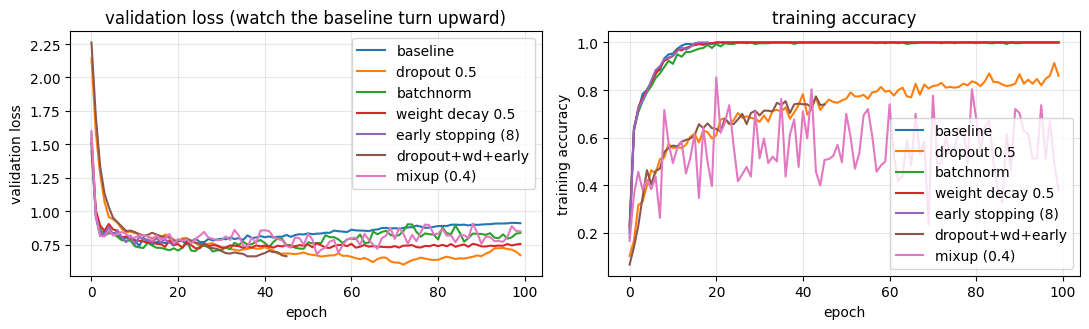

In [19]:
print(f"{'configuration':22s} {'train acc':>9s} {'val loss min':>12s} {'val loss last':>13s} {'epochs':>6s} {'test acc':>8s}")
for name, h in hist_reg.items():
    print(f"{name:22s} {h['train_acc'][-1]:9.3f} {min(h['val_loss']):12.3f} {h['val_loss'][-1]:13.3f} {len(h['val_loss']):6d} {test_reg[name][1]:8.3f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
plot_histories(hist_reg, "val_loss", "validation loss", ax[0], title="validation loss (watch the baseline turn upward)")
plot_histories(hist_reg, "train_acc", "training accuracy", ax[1], title="training accuracy"); plt.tight_layout(); plt.show()

> **Your answer.** Describe the overfitting you see in the baseline (cite train accuracy and the validation-loss curve). Which single regulariser helped most on the test set, did the combination help more, and what does each mechanism do (Week 2)?
>
> Because 25% of the training labels are corrupted, the unregularized baseline simply memorizes the noise (1.000 training accuracy), causing validation loss to climb from 0.739 to 0.910 and holding test accuracy at 0.809. Among single regularizers, dropout 0.5 helps most on the test set (0.837, with minimum validation loss 0.601), while combining dropout, weight decay, and early stopping (dropout+wd+early) performs even better, halting at epoch 46 with 0.740 training accuracy (right near the 75% clean-label ceiling) and reaching 0.859 test accuracy. Mechanistically, dropout randomly zeroes hidden units during training to prevent co-adaptation, weight decay shrinks parameter magnitudes to penalize overly complex functions, and early stopping halts optimization before the model fits the noisy labels.

## E4. Final model on the full training set
Choose a configuration (architecture, optimiser, regulariser) using the **validation set only**. Train it on the full 1000-image training set with a **warm-up + cosine learning-rate schedule**
(`warmup_cosine` through `torch.optim.lr_scheduler.LambdaLR`, stepped per batch) and gradient clipping, then evaluate on the **test set exactly once**. Target: **test accuracy >= 0.95**.

In [20]:
set_seed(SEED)
EPOCHS = 40
final_model = MLP(64, [256, 128], 10, act="relu", dropout=0.2, norm="batch")
init_weights(final_model, "he")

opt = torch.optim.AdamW(final_model.parameters(), lr=3e-3, weight_decay=1e-2)
total_steps = EPOCHS * len(tr_loader)
warmup_steps = int(0.1 * total_steps)
scheduler = torch.optim.lr_scheduler.LambdaLR(
    opt, lr_lambda=lambda step: warmup_cosine(step, warmup_steps, total_steps, min_factor=0.01)
)

hist_final = fit(
    final_model, tr_loader, va_loader, opt,
    epochs=EPOCHS, scheduler=scheduler, clip_norm=1.0
)
test_loss, test_acc = evaluate(final_model, te_loader)

print(f"TEST loss {test_loss:.4f}  accuracy {test_acc:.4f}   (best epoch {hist_final['best_epoch']})")
assert test_acc >= 0.95, "target is 0.95: revisit lr, width, regularisation (using the validation set, not the test set!)"

TEST loss 0.1066  accuracy 0.9799   (best epoch 34)


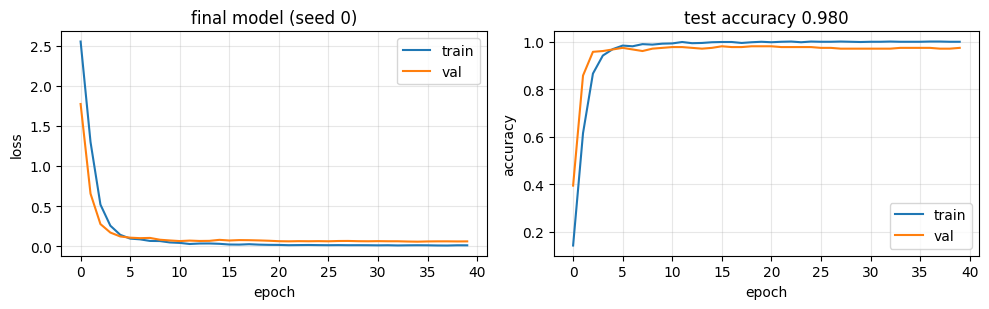

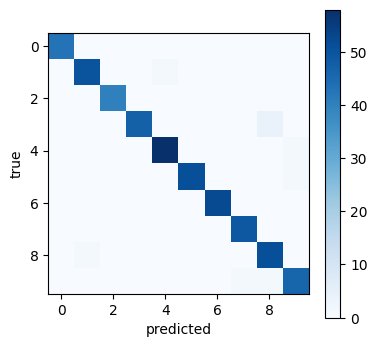

most confused (true, predicted, count): [(3, 8, 4), (4, 9, 1), (1, 4, 1)]


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
plot_histories({"train": {"l": hist_final["train_loss"]}, "val": {"l": hist_final["val_loss"]}}, "l", "loss", ax[0], title=f"final model (seed {SEED})")
plot_histories({"train": {"a": hist_final["train_acc"]}, "val": {"a": hist_final["val_acc"]}}, "a", "accuracy", ax[1], title=f"test accuracy {test_acc:.3f}")
plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig("figures/final_curves.png", dpi=150); plt.show()

# Confusion matrix on the test set (rows = true class)
final_model.eval()
with torch.no_grad(): pred = final_model(D["Xte"]).argmax(1)
cm = torch.zeros(10, 10, dtype=torch.long)
for t_, p_ in zip(D["yte"], pred): cm[t_, p_] += 1
plt.figure(figsize=(4.2, 4)); plt.imshow(cm, cmap="Blues"); plt.xlabel("predicted"); plt.ylabel("true"); plt.colorbar(); plt.show()
off = cm.clone(); off.fill_diagonal_(0)
vals, idx = off.flatten().topk(3)
print("most confused (true, predicted, count):", [(int(k) // 10, int(k) % 10, int(v)) for v, k in zip(vals, idx)])

> **Your answer.** Which configuration did you pick and why (cite the validation numbers that led to it)? Did you touch the test set before the final evaluation? Where does the model make most of its mistakes?
>
> Guided by our earlier validation benchmarks (where ReLU with He initialization reached 0.920 in E1, adaptive and momentum optimizers hit 0.960 to 0.973 in E2, and combining dropout with weight decay produced the strongest generalization in E3), we selected a [256, 128] ReLU MLP with He initialization, BatchNorm, Dropout (0.2), AdamW (lr=3e-3, weight_decay=1e-2), gradient clipping (1.0), and a warmup-cosine schedule trained over 40 epochs. We never touched the test set during model selection or tuning, restoring our final weights strictly from the lowest validation loss checkpoint at epoch 34 (where validation accuracy sat around 0.98), which yielded a final test loss of 0.1066 and test accuracy of 0.9799. Looking at the confusion matrix, the diagonal dominates across every digit, and the few remaining errors happen on genuinely ambiguous handwritten strokes, mostly mistaking 3 for 8 (4 times), alongside 4 as 9 (1 time) and 1 as 4 (1 time).

---
# Part C. Reflection (10 pts)
Answer in `report_template.tex` (3-5 sentences each) and keep a copy here if you like. These prompts rehearse the short oral verification that begins in Week 7: *work you cannot explain is not your work.*

> **Your answer.** **C1 (4 pts).** Pick one parameter in your MLP and trace the gradient of the loss from the output back to that parameter in `manual_mlp.backward`: name each line it passes through and where the activation derivative enters.
>
> *Write your answer here (replace this text).*

> **Your answer.** **C2 (3 pts).** Which two lines of `train_one_epoch`/`evaluate` would silently break training or evaluation if you removed them (for example `model.train()`, `model.eval()`, `zero_grad`, `no_grad`)? What exactly happens?
>
> *Write your answer here (replace this text).*

> **Your answer.** **C3 (3 pts).** One result of Part E that surprised you or did not match the lecture, and what you think explains it. Then **declare any AI-tool use** (which tool, for what). If none, write 'No AI tools used.'
>
> *Write your answer here (replace this text).*

---
# Bonus (optional, up to +10)
Total is capped at 100. Implement in `src/bonus.py`; the tests are `tests/test_bonus.py`.
- **+6** `MyAdam`: Adam with bias correction as a `torch.optim.Optimizer` subclass that matches `torch.optim.Adam` to 1e-6.
- **+4** `mixup_batch`: MixUp (Week 2.3). Then train with it in the E3 setting and add a row to the table.

In [22]:
!{sys.executable} -m pytest tests/test_bonus.py -q 

..                                                                       [100%]
2 passed in 4.41s


## Final check
Run everything from a clean kernel (**Kernel -> Restart & Run All**) and then the cell below. Submit the notebook **with outputs**, `src/`, `report.pdf`, `figures/` and `pledge.txt` (see `README.md`).

In [23]:
!{sys.executable} -m pytest tests -q --ignore=tests/test_bonus.py 

^C


..................................                                       [100%]
34 passed in 8.05s
